# WQF7009 Assignment 1: Using SHAP for Stroke Prediction Model
## Part 3: Neural Network (Black Box)

Author: Gan Yee Jing (25102061)

Creation Date: 2026-11-02

Trains a neural network (a black-box model) on the cleaned train/test files exported from `01_eda.ipynb`, then explains it with Kernel SHAP (Task 6): local explanations with force plots and the global explanation with a summary plot.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, balanced_accuracy_score, RocCurveDisplay)
from sklearn.model_selection import cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

sns.set_theme(style="whitegrid")

C:\Users\hp\Downloads\Master\02_Sem1\WQF7009 - Explainable Artificial Intelligence (XAI)\WQF7009---Assignment-1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### a) Load data

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

target = "stroke"
X_train, y_train = train.drop(columns=["id", target]), train[target]
X_test, y_test = test.drop(columns=["id", target]), test[target]

print(f"Train: {X_train.shape}, stroke rate {y_train.mean():.2%}")
print(f"Test:  {X_test.shape}, stroke rate {y_test.mean():.2%}")
X_train.head()

Train: (4087, 9), stroke rate 4.87%
Test:  (1022, 9), stroke rate 4.89%


,gender,age,hypertension,heart_disease,Residence_type,avg_glucose_level,bmi,smoking_status,bmi_missing
0,Female,48.0,0,0,Urban,69.21,33.1,never smoked,0
1,Female,29.0,0,0,Urban,84.19,21.2,never smoked,0
2,Female,35.0,0,0,Rural,119.40,22.9,never smoked,0
3,Male,38.0,0,0,Rural,108.68,32.7,never smoked,0
4,Male,14.0,0,0,Urban,82.34,31.6,Unknown,0


### b) Preprocessing and model
Same features and preprocessing as the logistic regression notebook:

| Feature type | Columns | Encoding |
|---|---|---|
| Numeric | `age`, `avg_glucose_level`, `bmi` | Standardised (fitted on train) |
| Categorical | `gender`, `Residence_type`, `smoking_status` | One-hot, first category dropped |
| Boolean | `hypertension`, `heart_disease`, `bmi_missing` | Unchanged |

**Model:** a neural network (`MLPClassifier`) with two hidden layers (32 and 16 neurons).
- It is a black box: its predictions come from many layered, non-linear weights, so they cannot be read directly like logistic regression coefficients.
- Balanced sample weights handle the class imbalance (~4.9% stroke), the same idea as `class_weight="balanced"` in logistic regression.
- `early_stopping=True` stops training when the validation score stops improving, to reduce overfitting.

In [3]:
num_cols = ["age", "avg_glucose_level", "bmi"]
cat_cols = ["gender", "Residence_type", "smoking_status"]  # ever_married and work_type dropped in 01_eda.ipynb
bin_cols = ["hypertension", "heart_disease", "bmi_missing"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
], verbose_feature_names_out=False)

model = Pipeline([
    ("preprocess", preprocess),
    ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-2, max_iter=500,
                          early_stopping=True, random_state=42)),
])
model.fit(X_train, y_train, mlp__sample_weight=compute_sample_weight("balanced", y_train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('mlp', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['gender','age','hypertension',...,'bmi','smoking_status','bmi_missing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `v

**Decision threshold**

The threshold is chosen from out-of-fold predictions on the training set, not from the test set.

In [4]:
weights = compute_sample_weight("balanced", y_train)
oof = cross_val_predict(model, X_train, y_train, cv=5, method="predict_proba",
                        params={"mlp__sample_weight": weights})[:, 1]
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flag = oof >= t
    rows.append({"threshold": t, "recall": flag[y_train == 1].mean(), "precision": y_train[flag].mean(),
                 "flagged": flag.mean()})
pd.DataFrame(rows).round(3)

,threshold,recall,precision,flagged
0,0.3,0.930,0.097,0.467
1,0.4,0.864,0.115,0.365
2,0.5,0.799,0.136,0.285
3,0.6,0.683,0.151,0.220
4,0.7,0.538,0.187,0.140
5,0.8,0.231,0.219,0.051


**Interpretation:** the trade-off is almost the same as for logistic regression. The default of 0.5 is kept: it detects about 80% of strokes in the training folds while flagging 28% of patients, the same balance as the logistic regression model.

### c) Evaluation

In [5]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print(f"Training stopped after {model.named_steps['mlp'].n_iter_} iterations (early stopping)")
print(f"Threshold: 0.5 (default), positive class support: {y_test.sum()} of {len(y_test)}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob):.3f}")
print(f"PR AUC (average precision): {average_precision_score(y_test, y_prob):.3f} (baseline {y_test.mean():.3f})")
print(f"Confusion matrix: TN {tn}, FP {fp}, FN {fn}, TP {tp}")
print()
print(classification_report(y_test, y_pred, target_names=["No stroke", "Stroke"], digits=3))

Training stopped after 29 iterations (early stopping)
Threshold: 0.5 (default), positive class support: 50 of 1022
Balanced accuracy: 0.757
ROC AUC: 0.841
PR AUC (average precision): 0.249 (baseline 0.049)
Confusion matrix: TN 713, FP 259, FN 11, TP 39

              precision    recall  f1-score   support

   No stroke      0.985     0.734     0.841       972
      Stroke      0.131     0.780     0.224        50

    accuracy                          0.736      1022
   macro avg      0.558     0.757     0.532      1022
weighted avg      0.943     0.736     0.811      1022



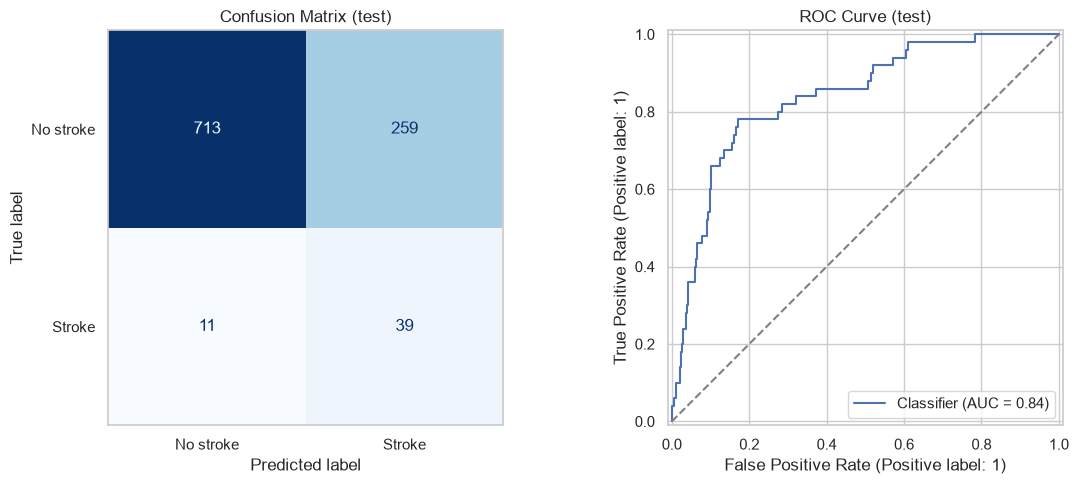

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["No stroke", "Stroke"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix (test)")
axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].plot([0, 1], [0, 1], ls="--", color="grey")
axes[1].set_title("ROC Curve (test)")
plt.tight_layout()
plt.show()

**Missed strokes (false negatives)**

In [7]:
missed = test[(y_test == 1) & (y_pred == 0)]
print(f"Missed strokes: {len(missed)} of {y_test.sum()}")
print(f"Age of missed strokes: median {missed['age'].median():.0f}, range {missed['age'].min():.0f} to {missed['age'].max():.0f}")
print(f"Age of detected strokes: median {test[(y_test == 1) & (y_pred == 1)]['age'].median():.0f}")
missed[['id', 'age', 'gender', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi_missing']].assign(
    probability=y_prob[missed.index]).round(3)

Missed strokes: 11 of 50
Age of missed strokes: median 42, range 14 to 59
Age of detected strokes: median 78


,id,age,gender,hypertension,heart_disease,avg_glucose_level,bmi_missing,probability
135,31563,38.0,Female,0,0,101.45,1,0.317
165,54385,45.0,Male,0,0,64.14,0,0.121
240,39912,32.0,Female,0,0,76.13,0,0.101
253,14499,47.0,Male,0,0,86.94,0,0.160
285,57419,59.0,Male,0,0,96.16,0,0.413
521,33943,39.0,Female,0,0,83.24,0,0.106
553,49669,14.0,Female,0,0,57.93,0,0.034
686,33879,42.0,Male,0,0,83.41,0,0.163
811,8154,57.0,Male,1,0,78.92,0,0.487
949,47306,58.0,Male,0,0,92.62,0,0.474


### d) Task 6: Kernel SHAP explainer

**1. Explainer used**
- `shap.KernelExplainer` (Kernel SHAP), because it is model-agnostic: it only needs the model's predictions, so it works on a black box like a neural network.
- It estimates SHAP values by hiding different combinations of features (replacing them with background values), watching how the prediction changes, and fitting a weighted linear model to those changes.

**2. Background data**
- The training set is summarised into 50 representative points with k-means, to keep the computation fast.
- A "hidden" feature takes its value from these background points, so explanations are relative to a typical training patient.

**3. Final prediction of a patient**

$$f(x) = \text{base value} + \sum_j \phi_j$$

- $\phi_j$: SHAP value of feature $j$, i.e. how much it pushes this patient's predicted probability up (+) or down (−)
- base value: the model's average predicted probability over the background data
- $f(x)$: this patient's predicted probability of stroke (here the explanation is directly in probability, not log-odds)

In [8]:
# Transform the data the same way the model sees it
feature_names = model.named_steps["preprocess"].get_feature_names_out()
X_train_t = pd.DataFrame(model.named_steps["preprocess"].transform(X_train), columns=feature_names, index=X_train.index)
X_test_t = pd.DataFrame(model.named_steps["preprocess"].transform(X_test), columns=feature_names, index=X_test.index)


def predict_stroke(X):
    """Predicted probability of stroke from the trained neural network."""
    return model.named_steps["mlp"].predict_proba(X)[:, 1]


# Create the explainer with a k-means summary of the training set as background
background = shap.kmeans(X_train_t, 50)
explainer = shap.KernelExplainer(predict_stroke, background)

# Explain the whole test set (seeded, because Kernel SHAP samples feature coalitions)
np.random.seed(42)
start = time.time()
shap_values = explainer(X_test_t, silent=True)
runtime = time.time() - start

# Show numeric features in original units in the plots
X_test_display = X_test_t.copy()
X_test_display[num_cols] = X_test[num_cols].values
shap_values.data = X_test_display.round(2).values

base = explainer.expected_value
print(f"Base value: {base:.3f} (average predicted probability)")
print("Model classes:", model.classes_, "-> explained output: predict_proba[:, 1] (stroke), identity link")
print("Background: 50 k-means centroids of", X_train_t.shape, "| explained:", X_test_t.shape,
      "| SHAP values:", shap_values.values.shape)
print(f"{2 * X_test_t.shape[1] + 2048} coalitions per patient (nsamples='auto'), l1_reg='num_features(10)' (default); runtime {runtime:.0f} s")

Base value: 0.292 (average predicted probability)
Model classes: [0 1] -> explained output: predict_proba[:, 1] (stroke), identity link
Background: 50 k-means centroids of (4087, 11) | explained: (1022, 11) | SHAP values: (1022, 11)
2070 coalitions per patient (nsamples='auto'), l1_reg='num_features(10)' (default); runtime 17 s


**Verification**

For an additive explanation, base value + sum of SHAP values must reproduce the model output on the explained scale (probability here).

In [9]:
reconstructed = shap_values.base_values + shap_values.values.sum(axis=1)
residual = np.abs(reconstructed - y_prob)
print(f"Feature names match: {list(X_test_t.columns) == list(shap_values.feature_names)}")
print(f"Max reconstruction residual: {residual.max():.2e} probability (tolerance 1e-6): "
      f"{'pass' if residual.max() < 1e-6 else 'FAIL'}")

Feature names match: True
Max reconstruction residual: 3.33e-16 probability (tolerance 1e-6): pass


### e) Local explanation (force plot)
Explains individual patients. One test patient is shown for each prediction outcome, picking the case where the model is most confident:

| Case | Actual | Predicted | Patient shown |
|---|---|---|---|
| True Positive (TP) | Stroke | Stroke | Highest predicted risk |
| True Negative (TN) | No stroke | No stroke | Lowest predicted risk |
| False Positive (FP) | No stroke | Stroke | Highest predicted risk (most confident false alarm) |
| False Negative (FN) | Stroke | No stroke | Lowest predicted risk (most confident miss) |

**How to read the force plot**
- The scale is predicted probability. `base value` is the average prediction; `f(x)` is this patient's prediction.
- Red features push the risk up; blue features push it down. Wider arrows mean a bigger effect.
- Only features with a noticeable contribution are labelled.

**Interpretation** (starting from base value 0.29, in probability)
- **TP (id 8213, 0.940):** the same patient as the logistic regression true positive: 78 years old, with missing BMI, heart disease and high glucose. Age adds most of the risk, followed by missing BMI.
- **TN (id 42938, 0.003):** an infant (age 0.64). Young age pulls the risk close to zero.
- **FP (id 49894, 0.931):** also the logistic regression false positive: a 78-year-old with missing BMI, hypertension, heart disease and high glucose but no recorded stroke.
- **FN (id 49669, 0.034):** the same 14-year-old missed by logistic regression. Young age pulls the risk down.

True Positive | id 8213 | actual: 1 | predicted: 1 | probability: 0.940


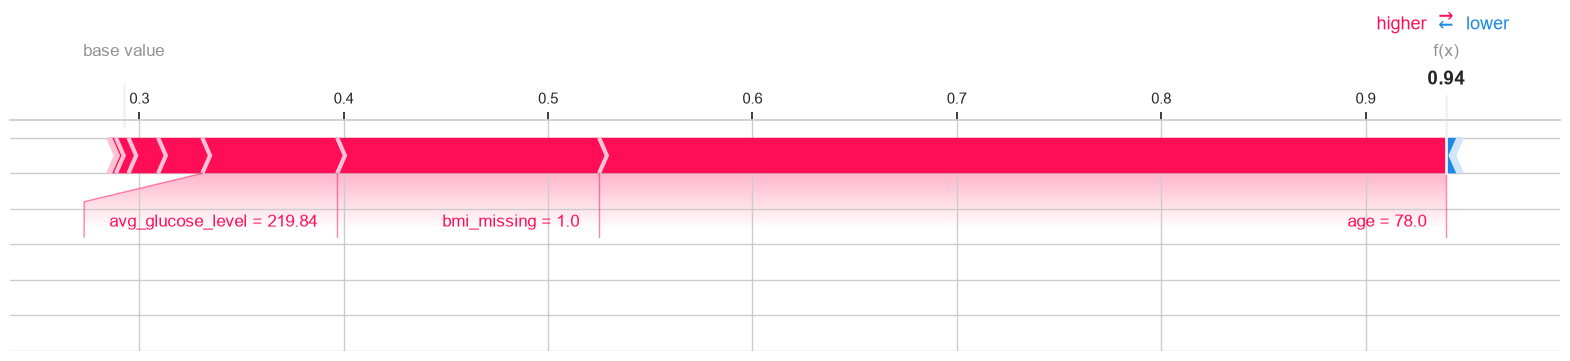

True Negative | id 42938 | actual: 0 | predicted: 0 | probability: 0.003


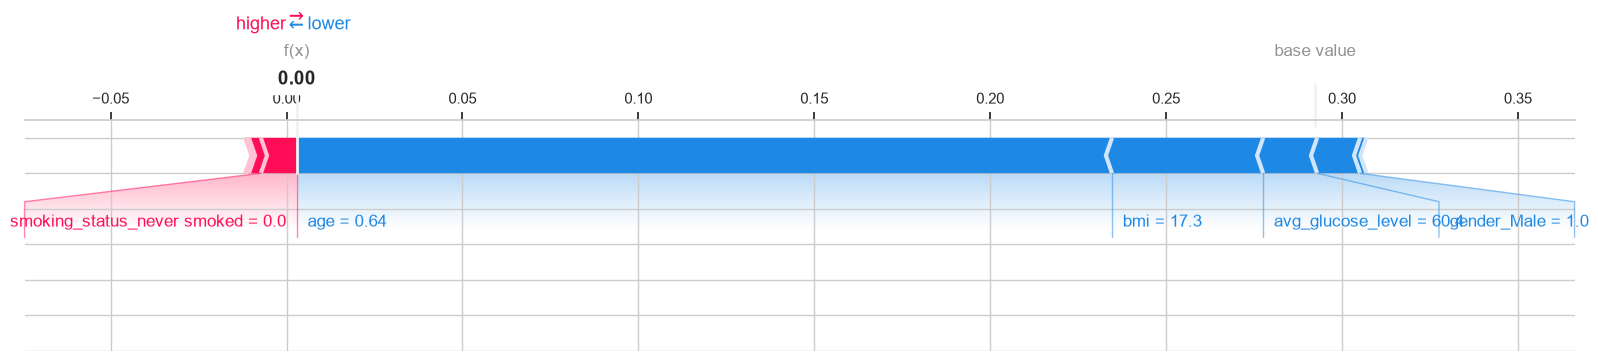

False Positive | id 49894 | actual: 0 | predicted: 1 | probability: 0.931


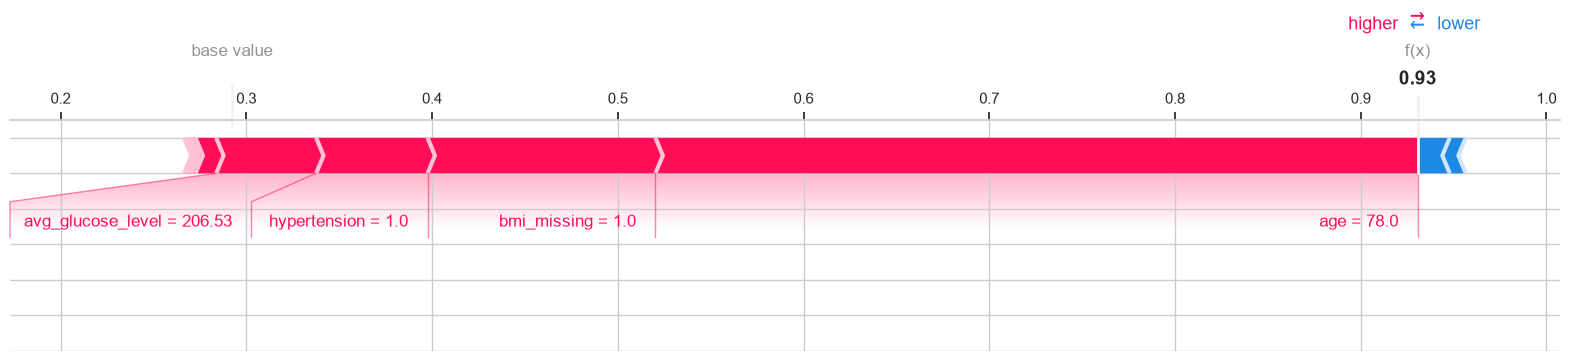

False Negative | id 49669 | actual: 1 | predicted: 0 | probability: 0.034


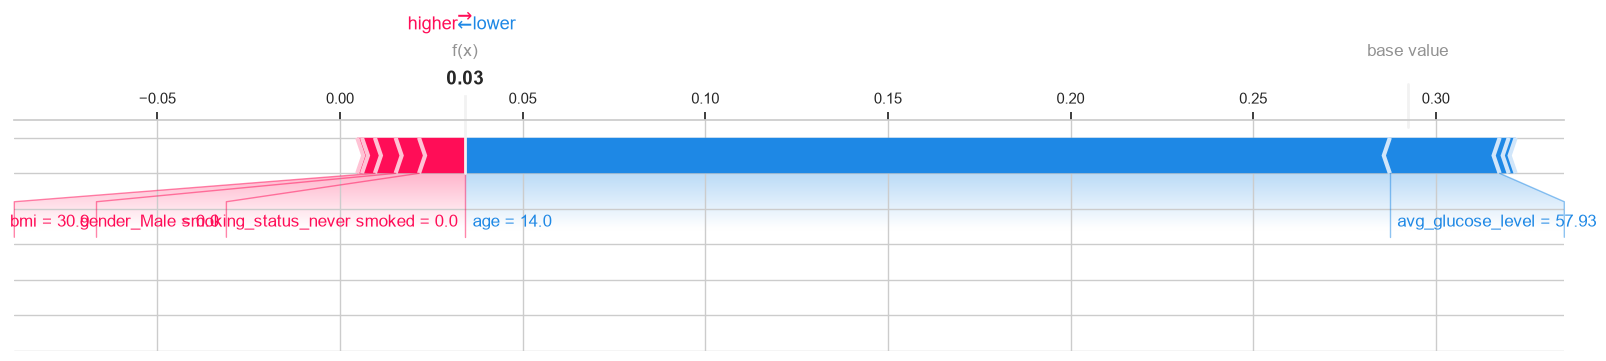

In [10]:
def plot_force(i, title):
    """Force plot for the i-th test patient."""
    print(f"{title} | id {test['id'].iloc[i]} | actual: {y_test.iloc[i]} | predicted: {y_pred[i]} | probability: {y_prob[i]:.3f}")
    shap.plots.force(shap_values[i], matplotlib=True, figsize=(20, 3), contribution_threshold=0.1)


actual, pred = y_test.values, y_pred
cases = {
    "True Positive":  (actual == 1) & (pred == 1),
    "True Negative":  (actual == 0) & (pred == 0),
    "False Positive": (actual == 0) & (pred == 1),
    "False Negative": (actual == 1) & (pred == 0),
}

for name, mask in cases.items():
    idx = np.where(mask)[0]
    # Most confident example of each case: highest risk for positive predictions, lowest for negative
    i = idx[np.argmax(y_prob[idx])] if name in ("True Positive", "False Positive") else idx[np.argmin(y_prob[idx])]
    plot_force(i, name)

**Single Prediction Analysis**

Feature contributions for this patient, largest first. The remaining features are combined into one row. The case is chosen by the same rule as in the logistic regression notebook (highest-risk true positive), so the two models can be compared on the same patient.

In [11]:
def contributions(sv, i, top=4):
    """Largest SHAP contributions for one patient, with the rest combined."""
    s = pd.DataFrame({"value": sv.data[i], "shap": sv.values[i]}, index=sv.feature_names)
    s = s.reindex(s["shap"].abs().sort_values(ascending=False).index)
    out = s.head(top).copy()
    out.loc["Remaining features combined"] = [np.nan, s["shap"].iloc[top:].sum()]
    out["direction"] = np.where(out["shap"] > 0, "increases", "decreases")
    return out.round(3)


tp = np.where((actual == 1) & (pred == 1))[0]
main = int(tp[np.argmax(y_prob[tp])])  # highest-risk true positive
print(f"Row {main}, id {test['id'].iloc[main]} | base {base:.3f} -> f(x) {y_prob[main]:.3f} probability, "
      f"check: {base + shap_values.values[main].sum():.3f}")
contributions(shap_values, main)

Row 207, id 8213 | base 0.292 -> f(x) 0.940 probability, check: 0.940


,value,shap,direction
age,78.00,0.415,increases
bmi_missing,1.00,0.128,increases
avg_glucose_level,219.84,0.066,increases
heart_disease,1.00,0.022,increases
Remaining features combined,NaN,0.017,increases


**Interpretation:** the MLP gives patient 8213 a probability of 0.940 (logistic regression: 0.969). The top four contributions are the same and in the same order: age (+0.415), missing BMI (+0.128), glucose (+0.066) and heart disease (+0.022), here in probability rather than log-odds.

### f) Global explanation (summary plot)
Combines the SHAP values of all test patients to show which features matter most overall.

**How to read the summary (beeswarm) plot**
- Features are ranked from most to least important (mean |SHAP value|).
- Each dot is one patient. Its position shows how much that feature pushed the predicted probability up (right) or down (left).
- Colour shows the feature value: red = high, blue = low. For example, red dots on the right mean high values raise the risk.

The bar plot shows the same ranking as a single number per feature (mean |SHAP value|), labelled with its share of the total.

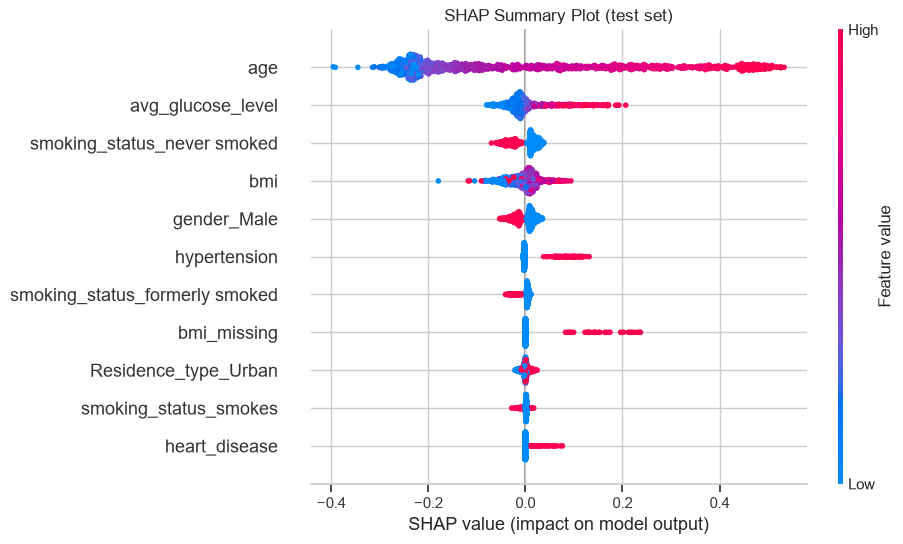

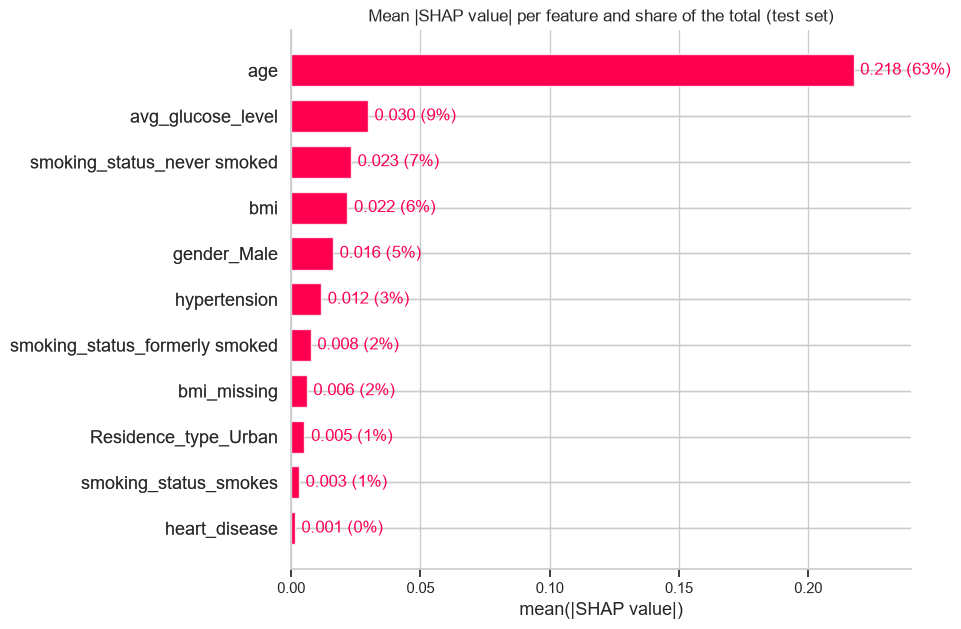

In [12]:
shap.plots.beeswarm(shap_values, max_display=len(feature_names), show=False)
plt.title("SHAP Summary Plot (test set)")
plt.show()

shap.plots.bar(shap_values, max_display=len(feature_names), show=False)
# Add each feature's share of the total mean |SHAP| to its bar label
ax = plt.gca()
mean_abs = pd.Series(np.abs(shap_values.values).mean(0), index=shap_values.feature_names)
share = mean_abs / mean_abs.sum() * 100
names = {round(t.get_position()[1]): t.get_text() for t in ax.get_yticklabels()}
for t in ax.texts:
    name = names[round(t.get_position()[1])]
    t.set_text(f"{mean_abs[name]:.3f} ({share[name]:.0f}%)")
plt.title("Mean |SHAP value| per feature and share of the total (test set)")
plt.show()

**Interpretation:** age alone accounts for 63% of the total mean |SHAP|, followed by glucose, never smoking, bmi and being male. In the beeswarm plot, high age and high glucose raise the predicted probability, while being a never-smoker or male lowers it. Unlike logistic regression, patients with the same feature value can get different SHAP values, because the neural network is non-linear and its features interact.

### g) Explanation stability
Repeats the explanation with a different background (a random 100-patient sample of the training set, seed 1, instead of the 50 k-means centroids) and checks whether the top features and the main case's contribution signs change.

In [13]:
alt_explainer = shap.KernelExplainer(predict_stroke, X_train_t.sample(100, random_state=1))
np.random.seed(42)
alt_values = alt_explainer(X_test_t, silent=True)
alt_values.data = shap_values.data

def top5(sv):
    """Five features with the largest mean |SHAP value|."""
    return pd.Series(np.abs(sv.values).mean(0), index=sv.feature_names).nlargest(5).index.tolist()


print(f"Base value: {base:.3f} (k-means) vs {alt_explainer.expected_value:.3f} (random sample)")
print("Top 5 (k-means):", top5(shap_values))
print("Top 5 (sample): ", top5(alt_values))
same_sign = np.sign(shap_values.values[main]) == np.sign(alt_values.values[main])
print(f"Main case: {same_sign.sum()} of {len(same_sign)} contributions keep their sign; changed:",
      [f for f, s in zip(feature_names, same_sign) if not s])

Base value: 0.292 (k-means) vs 0.302 (random sample)
Top 5 (k-means): ['age', 'avg_glucose_level', 'smoking_status_never smoked', 'bmi', 'gender_Male']
Top 5 (sample):  ['age', 'avg_glucose_level', 'smoking_status_never smoked', 'bmi', 'hypertension']
Main case: 11 of 11 contributions keep their sign; changed: []


**Interpretation:** the top 4 features are unchanged; 5th place changes from gender_Male to hypertension. All 11 contribution signs for the main case are unchanged, so the explanation is stable.

### h) Subgroup performance
Stroke recall and precision by gender and age group on the test set. Positive counts are small, so these are indicative only.

In [14]:
def subgroup_table(y_true, y_hat, groups):
    rows = []
    for name, g in groups.items():
        for level in sorted(g.unique()):
            m = (g == level).values
            yt, yp = y_true.values[m], y_hat[m]
            rows.append({"group": name, "level": level, "patients": m.sum(), "strokes": yt.sum(),
                         "recall": (yp[yt == 1] == 1).mean() if yt.sum() else np.nan,
                         "precision": yt[yp == 1].mean() if (yp == 1).sum() else np.nan})
    return pd.DataFrame(rows).round(3)


age_group = pd.cut(X_test["age"], [0, 60, 120], right=False, labels=["under 60", "60 and over"]).astype(str)
subgroup_table(y_test, y_pred, {"gender": X_test["gender"], "age": age_group})

,group,level,patients,strokes,recall,precision
0,gender,Female,597,29,0.828,0.140
1,gender,Male,425,21,0.714,0.119
2,age,60 and over,275,38,1.000,0.158
3,age,under 60,747,12,0.083,0.017


**Interpretation:** as with logistic regression, recall is similar for women (0.83) and men (0.71), but all 38 strokes in patients aged 60 and over are detected and only 1 of 12 in patients under 60 (0.08).